# 03 · Cohort descriptives

Placement rate by branch, CGPA band, backlogs and internships: the context table for the report.

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.precision", 3)

# Use the real processed dataset when it exists, otherwise the synthetic demo.
REAL = ROOT / "placeiq-data/processed/historical.csv"
DATA = REAL if REAL.exists() else ROOT / "placeiq-data/synthetic/historical.csv"
SYNTHETIC = DATA != REAL
print("Data:", DATA.relative_to(ROOT), "(SYNTHETIC - do not report)" if SYNTHETIC else "(real)")

Data: placeiq-data\synthetic\historical.csv (SYNTHETIC - do not report)


In [2]:
df = pd.read_csv(DATA)
df["cgpa_band"] = pd.cut(df.cgpa, [0, 6.5, 7, 7.5, 8, 8.5, 10.01], right=False)
def rate(col):
    return df.groupby(col, observed=True)["placed"].agg(students="count", placement_rate="mean")
display(rate("branch"))
display(rate("cgpa_band"))
display(rate("active_backlogs"))
display(rate("internships"))

,students,placement_rate
branch,,
CSE,111,0.649
ECE,58,0.534
EEE,31,0.645
IT,74,0.649
ME,26,0.615


,students,placement_rate
cgpa_band,,
"[0.0, 6.5)",51,0.157
"[6.5, 7.0)",42,0.452
"[7.0, 7.5)",64,0.734
"[7.5, 8.0)",67,0.716
"[8.0, 8.5)",42,0.833
"[8.5, 10.01)",34,0.882


,students,placement_rate
active_backlogs,,
0,193,0.777
1,74,0.446
2,24,0.167
3,7,0.000
4,1,0.000
5,1,0.000


,students,placement_rate
internships,,
0,143,0.552
1,104,0.644
2,37,0.730
3,13,0.846
4,1,1.000
5,2,1.000


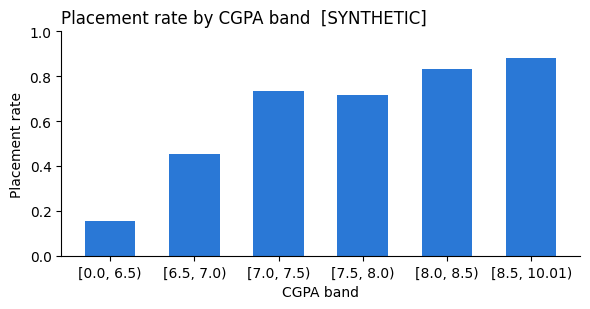

In [3]:
import matplotlib.pyplot as plt
r = rate("cgpa_band")
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(r.index.astype(str), r.placement_rate, color="#2a78d6", width=0.6)
ax.set_ylabel("Placement rate"); ax.set_xlabel("CGPA band"); ax.set_ylim(0, 1)
ax.set_title("Placement rate by CGPA band" + ("  [SYNTHETIC]" if SYNTHETIC else ""), loc="left")
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()